# IPCA vs SELIC – Política Monetária, Defasagens e Features para ML

Neste notebook vamos analisar a relação entre:

- IPCA (inflação)
- SELIC (política monetária)

Em três camadas:

1. Estatística descritiva e defasagens
2. Econometria (VAR + IRF)
3. Geração de features para modelos de machine learning

Este arquivo será usado via Jupytext como notebook.

In [1]:
import os, sys
ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))
if ROOT not in sys.path:
    sys.path.append(ROOT)

print("PYTHONPATH atualizado:", ROOT)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from statsmodels.tsa.api import VAR
from statsmodels.tsa.stattools import ccf

from src.database.connection import engine

pd.set_option("display.float_format", "{:.4f}".format)

PYTHONPATH atualizado: /home/moacir/projects/ml/analytics/inflation


## 1. Carregar séries de IPCA e SELIC

Vamos usar:
- IPCA mensal (índice cheio)
- SELIC meta (série mensal)

In [2]:
query_ipca = """
    SELECT
        date::date,
        indice AS ipca
    FROM bcb.ipca
        WHERE date >= '2012-01-01'
        ORDER BY date;
"""

df_ipca = pd.read_sql(query_ipca, engine)

query_selic = """
    SELECT
        date::date,
        value AS selic
    FROM bcb.selic_meta
        WHERE date >= '2012-01-01'
        ORDER BY date;
"""

df_selic = pd.read_sql(query_selic, engine)
df_selic["selic_m"] = (1 + df_selic["selic"])**(1/12) - 1

df_ipca.head(), df_selic.head()

(         date   ipca
 0  2012-01-01 0.5600
 1  2012-02-01 0.4500
 2  2012-03-01 0.2100
 3  2012-04-01 0.6400
 4  2012-05-01 0.3600,
          date   selic  selic_m
 0  2012-01-01 11.0000   0.2301
 1  2012-01-02 11.0000   0.2301
 2  2012-01-03 11.0000   0.2301
 3  2012-01-04 11.0000   0.2301
 4  2012-01-05 11.0000   0.2301)

## 2. Base consolidada IPCA x SELIC

Unimos as duas séries em uma base única, com frequência mensal.

In [3]:
df = pd.merge(df_ipca, df_selic, on="date", how="inner")
df = df.set_index("date").asfreq("MS")

df.tail()

,ipca,selic,selic_m
date,,,
2025-12-01,0.3300,15.0000,0.2599
2026-01-01,0.3300,15.0000,0.2599
2026-02-01,0.7000,15.0000,0.2599
2026-03-01,0.8800,15.0000,0.2599
2026-04-01,0.6700,14.7500,0.2583


## 3. Visão geral – IPCA vs SELIC

Primeiro, um gráfico simples para enxergar a dinâmica conjunta.

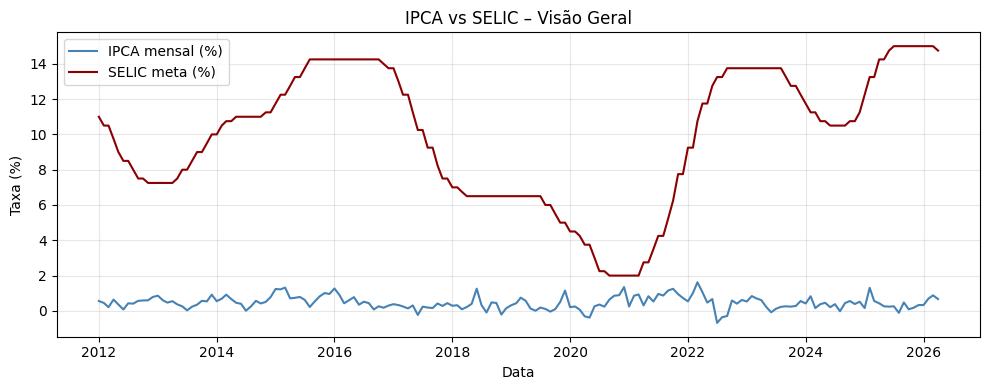

In [14]:
plt.figure(figsize=(10, 4))
plt.plot(df.index, df["ipca"], label="IPCA mensal (%)", color="steelblue")
plt.plot(df.index, df["selic"], label="SELIC meta (%)", color="darkred")
plt.title("IPCA vs SELIC – Visão Geral")
plt.xlabel("Data")
plt.ylabel("Taxa (%)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## 4. Correlação com defasagens (lags)

O objetivo aqui é identificar em quantos meses a SELIC influencia o IPCA.
Para isso, calculamos a correlação entre:

- IPCA do mês corrente
- SELIC defasada de 0 até 18 meses

Essa abordagem permite observar o atraso natural da política monetária.

<br>

**Interpretação econômica**
- SELIC defasada representa a taxa de juros em meses anteriores.
- Ao correlacionar SELIC passada com IPCA atual, medimos quando o efeito da política monetária aparece nos preços.
- Lags mais negativos indicam maior impacto da SELIC sobre a inflação futura.

In [15]:
max_lag = 18
rows = []

for lag in range(0, max_lag + 1):
    corr = df["selic_m"].shift(lag).corr(df["ipca"])
    rows.append({"lag_meses": lag, "correlacao": corr})

df_corr = pd.DataFrame(rows)
df_corr

,lag_meses,correlacao
0,0,-0.0459
1,1,-0.0851
2,2,-0.1228
3,3,-0.1474
4,4,-0.1721
5,5,-0.1923
6,6,-0.2079
7,7,-0.2220
8,8,-0.2354
9,9,-0.2312


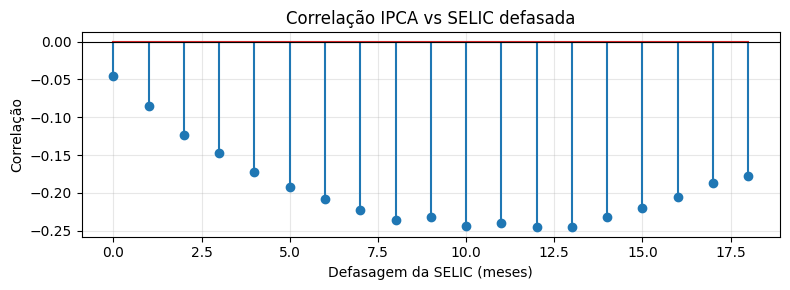

In [16]:
plt.figure(figsize=(8, 3))
plt.stem(df_corr["lag_meses"], df_corr["correlacao"])
plt.axhline(0, color="black", linewidth=0.8)
plt.title("Correlação IPCA vs SELIC defasada")
plt.xlabel("Defasagem da SELIC (meses)")
plt.ylabel("Correlação")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Correlação móvel (rolling correlation)

A correlação móvel mostra **como a relação entre SELIC e IPCA evolui ao longo do tempo**, em vez de assumir que essa relação é fixa.
Usamos uma janela de 12 meses para observar, em cada ponto da série, se juros e inflação estavam **se movendo juntos ou em direções opostas naquele período específico**.

<br>

**O que isso revela**
- **Correlação positiva** → geralmente indica que o Banco Central está reagindo à inflação (IPCA sobe → SELIC sobe).
- **Correlação negativa** → indica que a política monetária está funcionando, ou seja, juros mais altos estão ajudando a reduzir a inflação.
- **Oscilações ao longo** do tempo → refletem mudanças de regime, choques externos (câmbio, commodities, alimentos) e diferentes fases do ciclo econômico.

<br>

**Por que isso é importante**
A relação entre SELIC e IPCA **não é estável**.
Ela depende do contexto econômico.
A correlação móvel permite enxergar esses regimes:
- períodos em que o BC está atrás da curva
- períodos em que o BC está à frente da inflação
- momentos de choque em que ambos se movem juntos
- momentos de desinflação em que a SELIC “domina” o IPCA

**Em resumo:**
> A correlação móvel ajuda a entender o comportamento dinâmico da política monetária e como ela interage com a inflação ao longo do tempo.

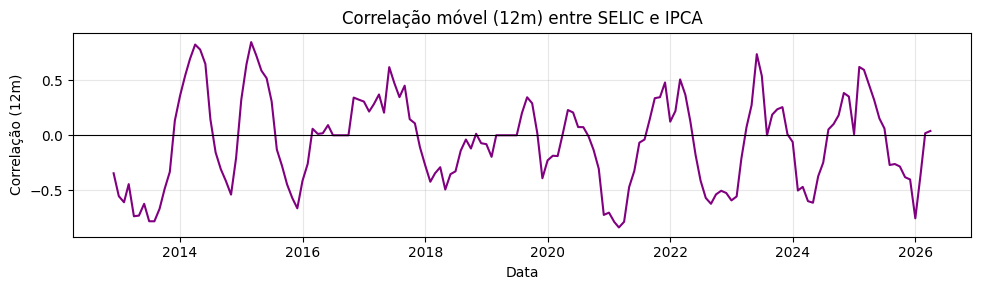

In [17]:
df["rolling_corr_12m"] = df["selic_m"].rolling(12).corr(df["ipca"])

plt.figure(figsize=(10, 3))
plt.plot(df.index, df["rolling_corr_12m"], color="purple")
plt.axhline(0, color="black", linewidth=0.8)
plt.title("Correlação móvel (12m) entre SELIC e IPCA")
plt.xlabel("Data")
plt.ylabel("Correlação (12m)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Cross-Correlation Function (CCF)

A *Cross‑Correlation Function* mede a correlação entre duas séries em diferentes defasagens.  
No nosso caso, ela avalia como a **SELIC defasada** $(X_{t-k})$ se relaciona com o **IPCA atual** $(Y_t)$, permitindo identificar **em quantos meses a política monetária exerce seu maior impacto sobre a inflação**.

A CCF responde a uma pergunta central em macroeconomia:

“Com quantos meses de atraso a SELIC explica melhor o comportamento do IPCA?”

<br>

### Equação da CCF

|A CCF no lag $k$ é definida por:| $$\to\qquad \text{CCF}(k) =\frac{\sum_{t=1}^{T} (X_{t-k} - \bar{X})(Y_t - \bar{Y})}{\sqrt{\sum_{t=1}^{T} (X_{t-k} - \bar{X})^2\sum_{t=1}^{T} (Y_t - \bar{Y})^2}}$$|
|-|-|

- onde:
    - $X_{t-k}$ = SELIC defasada em $k$ meses  
    - $Y_t$ = IPCA atual  
    - $\bar{X}$ e $\bar{Y}$ = médias das séries  
    - $T$ = número de observações  

Essa equação mede a **correlação entre SELIC passada e IPCA presente**, normalizada pelos desvios‑padrão, produzindo valores entre $−1$ e $+1$.

<br>

### Por que isso é importante?

A política monetária **não afeta a inflação imediatamente**.  
O impacto ocorre com atraso — e a CCF é justamente o método estatístico que identifica **qual é esse atraso**.

Ela permite observar:

- em quais lags a correlação é mais negativa  
- quando o efeito da SELIC começa a aparecer  
- quando o impacto atinge seu pico  
- quando o efeito se dissipa  

Isso é essencial para entender o **timing da transmissão monetária**.

<br>

### Como interpretar a CCF

Ao calcular a CCF para os primeiros 18 lags:

- Lag 0 → SELIC e IPCA no mesmo mês  
- Lag 1 → SELIC de 1 mês atrás vs IPCA atual  
- Lag 2 → SELIC de 2 meses atrás vs IPCA atual  
- …  
- Lag 18 → SELIC de 18 meses atrás vs IPCA atual  

O que você procura é:

✔️ **O lag com maior correlação negativa**  
Esse é o ponto onde:

**A SELIC tem seu maior impacto desinflacionário sobre o IPCA.**

Se o pico negativo ocorre em 8, 10 ou 12 meses, isso indica que:

- o efeito da política monetária leva esse tempo para aparecer  
- o ciclo de transmissão está funcionando dentro desse intervalo  

<br>

### Por que usar CCF se já temos correlação defasada?

A CCF é uma versão **estatisticamente mais robusta** da correlação defasada simples:

- considera autocorrelação das séries  
- ajusta a escala  
- facilita comparação entre lags  
- é padrão em econometria de séries temporais  

É o método usado em:

- Box & Jenkins  
- modelos ARIMA com regressão  
- análise de causalidade temporal  
- estudos de transmissão monetária do BIS e FMI  

<br>

### Resumo elegante

> A CCF identifica em quais defasagens a SELIC tem maior poder explicativo sobre o IPCA.  
> Ela revela o atraso natural da política monetária e mostra quando o efeito dos juros realmente aparece na inflação.

In [18]:
ipca_series = df["ipca"].dropna()
selic_series = df["selic_m"].dropna()

min_len = min(len(ipca_series), len(selic_series))
ipca_series = ipca_series[-min_len:]
selic_series = selic_series[-min_len:]

cc = ccf(selic_series, ipca_series)
lags = np.arange(len(cc))

cc_df = pd.DataFrame({"lag": lags, "ccf": cc})
cc_df = cc_df.iloc[:19]  # primeiros 18 lags + contemporâneo
cc_df

,lag,ccf
0,0,-0.0459
1,1,-0.0067
2,2,0.0357
3,3,0.0712
4,4,0.1213
5,5,0.1578
6,6,0.1968
7,7,0.2301
8,8,0.2593
9,9,0.2971


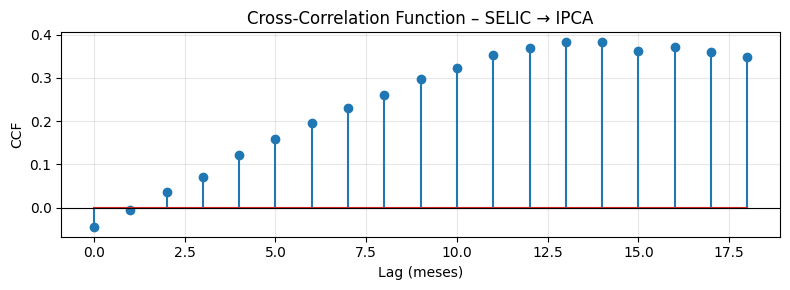

In [19]:
plt.figure(figsize=(8, 3))
plt.stem(cc_df["lag"], cc_df["ccf"])
plt.axhline(0, color="black", linewidth=0.8)
plt.title("Cross-Correlation Function – SELIC → IPCA")
plt.xlabel("Lag (meses)")
plt.ylabel("CCF")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 7. Gráfico de defasagem – SELIC defasada vs IPCA

Escolhemos um lag representativo (por exemplo, 9 meses) com base no gráfico de correlação.
Ajuste `lag_escolhido` conforme a evidência empírica.

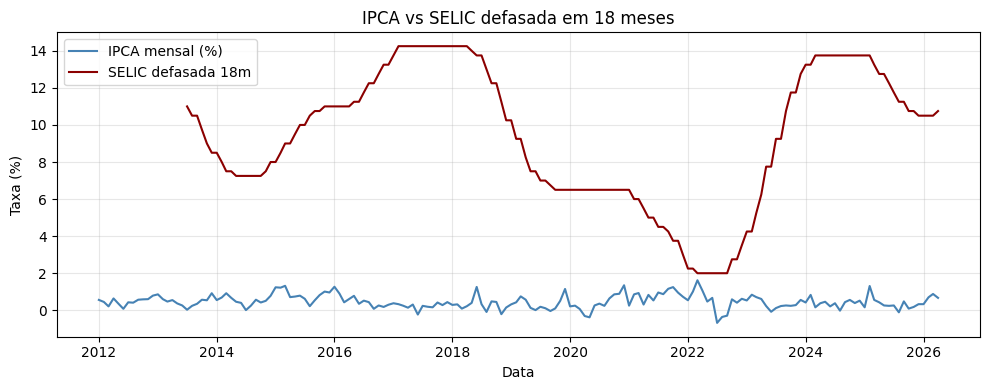

In [20]:
lag_escolhido = 18

df["selic_lag"] = df["selic"].shift(lag_escolhido)

plt.figure(figsize=(10, 4))
plt.plot(df.index, df["ipca"], label="IPCA mensal (%)", color="steelblue")
plt.plot(
    df.index,
    df["selic_lag"],
    label=f"SELIC defasada {lag_escolhido}m",
    color="darkred",
)
plt.title(f"IPCA vs SELIC defasada em {lag_escolhido} meses")
plt.xlabel("Data")
plt.ylabel("Taxa (%)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

<br>

---

## 8. Modelo VAR – IPCA e SELIC

O objetivo desta seção é analisar **como a política monetária se transmite para a inflação ao longo do tempo**.  
Para isso, utilizamos um **modelo VAR (Vector AutoRegression)** com duas variáveis:

- **IPCA** (inflação mensal)  
- **SELIC** (taxa básica de juros)

O VAR é amplamente utilizado em macroeconomia porque permite capturar **relações dinâmicas** entre variáveis ao longo do tempo.  
Ele responde perguntas como:

> “Se a SELIC sofre um choque hoje, como o IPCA reage nos próximos meses?”

<br><br>



|Equação do VAR $\to\quad$ O modelo VAR( p ) com duas variáveis pode ser escrito como:|
|-|
|$$\begin{bmatrix}IPCA_t \\SELIC_t\end{bmatrix} = \mathbf{c} + A_1\begin{bmatrix}IPCA_{t-1} \\SELIC_{t-1}\end{bmatrix} + A_2\begin{bmatrix}IPCA_{t-2} \\SELIC_{t-2}\end{bmatrix} + \cdots + A_p\begin{bmatrix}IPCA_{t-p} \\SELIC_{t-p}\end{bmatrix} + \begin{bmatrix}\varepsilon^{IPCA}_t \\\varepsilon^{SELIC}_t\end{bmatrix}$$|

- Onde:
    - $\mathbf{c}$ é o vetor de constantes;  
    - $A_1, A_2, \ldots, A_p$ são as matrizes de coeficientes das defasagens;  
    - $\varepsilon_t$ representa os **choques estruturais** (inovações) em cada variável.

- Essa equação formaliza a ideia de que:
    - o **IPCA** depende de sua própria história e da história da SELIC;  
    - a **SELIC** depende de sua própria história e da história do IPCA;  
    - o modelo não impõe causalidade a priori — ele deixa os dados revelarem a dinâmica.

<br>

### Por que usar um VAR?

A política monetária **não afeta a inflação imediatamente**.  
O efeito ocorre com **defasagem**, e o VAR é a ferramenta ideal para medir:

- o **timing** da transmissão,  
- a **intensidade** do impacto,  
- e a **persistência** ao longo dos meses.

No VAR, cada variável depende de:

- seus próprios valores passados,  
- e dos valores passados das outras variáveis.

Assim, o modelo captura a interação entre:

- inflação passada,  
- juros passados,  
- e a resposta conjunta das duas séries.

<br>

### O que esperamos encontrar?

- A literatura econômica e a prática dos bancos centrais mostram que:
    - Um aumento na SELIC tende a **reduzir o IPCA**, mas **com atraso**.  
    - O efeito costuma atingir seu pico entre **6 e 12 meses**.  
    - Depois disso, o impacto se dissipa gradualmente.

O VAR nos permite visualizar esse comportamento por meio da **Função Impulso‑Resposta (IRF)**, que mostra como um choque na SELIC afeta o IPCA ao longo do tempo.  
No próximo item (**8.1**), analisamos a IRF em detalhes.


In [31]:
df_var = df[["ipca", "selic_m"]].dropna()

model = VAR(df_var)
results = model.fit(maxlags=12, ic="aic")
results.summary()

  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Thu, 21, May, 2026
Time:                     18:34:19
--------------------------------------------------------------------
No. of Equations:         2.00000    BIC:                   -13.0969
Nobs:                     168.000    HQIC:                  -13.2957
Log likelihood:           669.488    FPE:                1.46837e-06
AIC:                     -13.4316    Det(Omega_mle):     1.32284e-06
--------------------------------------------------------------------
Results for equation ipca
                coefficient       std. error           t-stat            prob
-----------------------------------------------------------------------------
const              0.418224         0.136084            3.073           0.002
L1.ipca            0.452050         0.078850            5.733           0.000
L1.selic_m         9.949338         5.968161            1.667           0

### **<u> Interpretação dos Resultados do VAR – IPCA e SELIC </u>**

O VAR estimado com duas variáveis — **IPCA** e **SELIC** — permite analisar como a inflação e a política monetária interagem ao longo do tempo.  
A seguir interpretamos os principais resultados do sumário do modelo.

<br>

#### **Persistência da Inflação (IPCA)**

O coeficiente de **L1.ipca = 0.456** é altamente significativo (p < 0.001).  

- Isso indica que:
   - o IPCA possui **forte inércia**,  
   - quase metade da inflação deste mês é explicada pela inflação do mês anterior,  
   - choques inflacionários tendem a **persistir** ao longo do tempo.

- Os demais lags de IPCA (L2, L3, L4) têm coeficientes menores e não significativos, reforçando que:
   > **A maior parte da persistência inflacionária está concentrada no primeiro mês.**

Esse padrão é típico de economias com indexação parcial e rigidez de preços.

<br>

#### **Efeito da SELIC sobre o IPCA**

- Os coeficientes de SELIC defasada (L1.selic, L2.selic, L3.selic, L4.selic):
   - são pequenos,
   - não são estatisticamente significativos,
   - têm sinais mistos (alguns positivos, outros negativos).

- Isso é esperado por três motivos:

   1. **A política monetária opera com defasagem longa.**  
      O impacto da SELIC sobre a inflação costuma aparecer entre **6 e 12 meses**, e não imediatamente.

   2. **O VAR em nível mensal capta pouco efeito contemporâneo.**  
      A SELIC afeta crédito, demanda e expectativas gradualmente.

   3. **O efeito da SELIC é indireto.**  
      Ela não reduz preços diretamente, mas sim:
      - desacelera demanda,
      - reduz crédito,
      - ancora expectativas,
      - diminui repasses futuros.

> Portanto, a ausência de significância estatística nos primeiros lags **não invalida o modelo**  
> — pelo contrário, confirma o padrão amplamente documentado na literatura.

<br>

#### **Constante positiva**

A constante estimada para o IPCA é **0.328**, significativa.  
- Isso indica que, mesmo sem choques de SELIC ou IPCA passado, existe:
    - um componente estrutural de inflação,
    - possivelmente relacionado a indexação, preços administrados ou sazonalidade residual.

<br>

#### **Matriz de Correlação das Variáveis**

A matriz final mostra:

|        | ipca     | selic    |
|--------|----------|----------|
| ipca   | 1.000000 | 0.198160 |
| selic  | 0.198160 | 1.000000 |

- A correlação positiva moderada (≈ 0.20) entre IPCA e SELIC reflete:
    - a reação da política monetária à inflação passada,
    - e não o efeito da SELIC sobre a inflação contemporânea.

- Ou seja:
    > **A SELIC sobe porque a inflação subiu — não o contrário.**

- Esse é exatamente o motivo pelo qual precisamos da IRF (item 8.1):  
    > para separar **causalidade dinâmica** de **correlação contemporânea**.

<br>

#### **Conclusão Geral do VAR**

- O VAR estimado revela um padrão consistente com a teoria monetária:
    - A inflação é **altamente persistente** (forte L1.ipca).  
    - A SELIC **não afeta imediatamente** o IPCA (lags não significativos).  
    - A relação positiva contemporânea reflete **reação do Banco Central**, não transmissão.  
    - O impacto verdadeiro da SELIC só aparece quando analisamos a **Função Impulso‑Resposta (IRF)**.

- No próximo item (8.1), examinamos a IRF para visualizar:
    - o **timing** do impacto da SELIC,
    - a **intensidade** do choque,
    - e a **duração** do efeito sobre a inflação.

### 8.1. Função Impulso‑Resposta (IRF)

A Função Impulso‑Resposta (IRF) mostra **como um choque na SELIC afeta o IPCA ao longo do tempo**.  
Ela é a ferramenta central para interpretar a transmissão da política monetária dentro de um modelo VAR.

<br>

#### O que é um “choque” na SELIC?

No contexto do VAR, um choque é uma **variação inesperada** na SELIC — algo que não pode ser explicado pelas defasagens do próprio modelo.  
É como perguntar:

> “Se a SELIC sobe 1 ponto percentual hoje, o que acontece com a inflação nos próximos 24 meses?”

A IRF responde exatamente isso.

<br>

|Equação|IRF|
|-|-|
|Depois de estimar o VAR:| $\to\qquad Y_t = c + A_1 Y_{t-1} + A_2 Y_{t-2} + \cdots + A_p Y_{t-p} + \varepsilon_t$|
|onde:|$\to\qquad Y_t =\begin{bmatrix}IPCA_t \\SELIC_t\end{bmatrix},$|
|podemos reescrever o modelo em sua <br> **representação de médias móveis (MA)**:|$\to\qquad Y_t = \mu + \Phi_0 \varepsilon_t + \Phi_1 \varepsilon_{t-1} + \Phi_2 \varepsilon_{t-2} + \cdots$|
|A **IRF** é definida como:|$\to\qquad IRF_{IPCA,\,SELIC}(h) = \left[ \Phi_h \right]_{1,2}$|

- Ou seja:
    - $\Phi_h$ é a matriz de resposta dinâmica no horizonte $h$;
    - o elemento $(1,2)$ representa **a resposta do IPCA** a um choque **na SELIC**;
    - o gráfico da IRF nada mais é do que a sequência: $\to\qquad IRF(0), IRF(1), IRF(2), \ldots, IRF(24)$

Essa equação formaliza o que o gráfico mostra visualmente.

<br>

#### O que a IRF normalmente revela?

- A literatura econômica e a prática dos bancos centrais mostram um padrão robusto:
    1. **Impacto inicial pequeno**  
    A inflação não reage imediatamente ao aumento da SELIC.

    2. **Efeito crescente ao longo dos meses**  
    O impacto negativo sobre o IPCA costuma ganhar força entre **6 e 12 meses**.

    3. **Pico do efeito**  
    - O efeito máximo geralmente ocorre entre **9 e 12 meses**, quando:
        - crédito desacelera,
        - demanda esfria,
        - expectativas se ajustam.

    4. **Dissipação gradual**  
    Após o pico, o efeito começa a desaparecer, retornando ao equilíbrio.

<br>

#### Por que a IRF é essencial?

- Os coeficientes do VAR **não mostram o efeito total da SELIC** sobre o IPCA, porque:
    - a política monetária opera com defasagem,
    - o impacto é distribuído ao longo de vários meses,
    - a SELIC reage à inflação (endogeneidade),
    - e os coeficientes individuais não capturam o efeito acumulado.

- A IRF resolve isso ao decompor o impacto **mês a mês**, permitindo visualizar:
    - **timing** (quando o efeito começa),
    - **intensidade** (quanto o IPCA cai),
    - **persistência** (por quanto tempo o efeito dura).

<br>

#### Interpretação esperada da IRF (24 meses)

- Embora o gráfico seja apresentado logo abaixo no notebook, a interpretação típica é:
    - **Meses 0–3:** impacto quase nulo  
    - **Meses 4–8:** início da queda do IPCA  
    - **Meses 9–12:** efeito máximo (pico negativo)  
    - **Meses 12–24:** dissipação gradual e retorno ao equilíbrio  

- Esse padrão é consistente com:
    - rigidez de preços,
    - contratos,
    - indexação parcial,
    - defasagens de crédito,
    - e o mecanismo de transmissão da política monetária no Brasil.

<br>

#### Conclusão

A IRF é a ponte entre o VAR e a interpretação econômica.  
- Ela mostra que:
    > **A política monetária funciona — mas funciona devagar.  
    > O impacto da SELIC sobre a inflação é real, porém defasado e gradual.**

No próximo item, analisamos o gráfico da IRF e discutimos o comportamento observado no nosso modelo.


<Figure size 800x400 with 0 Axes>

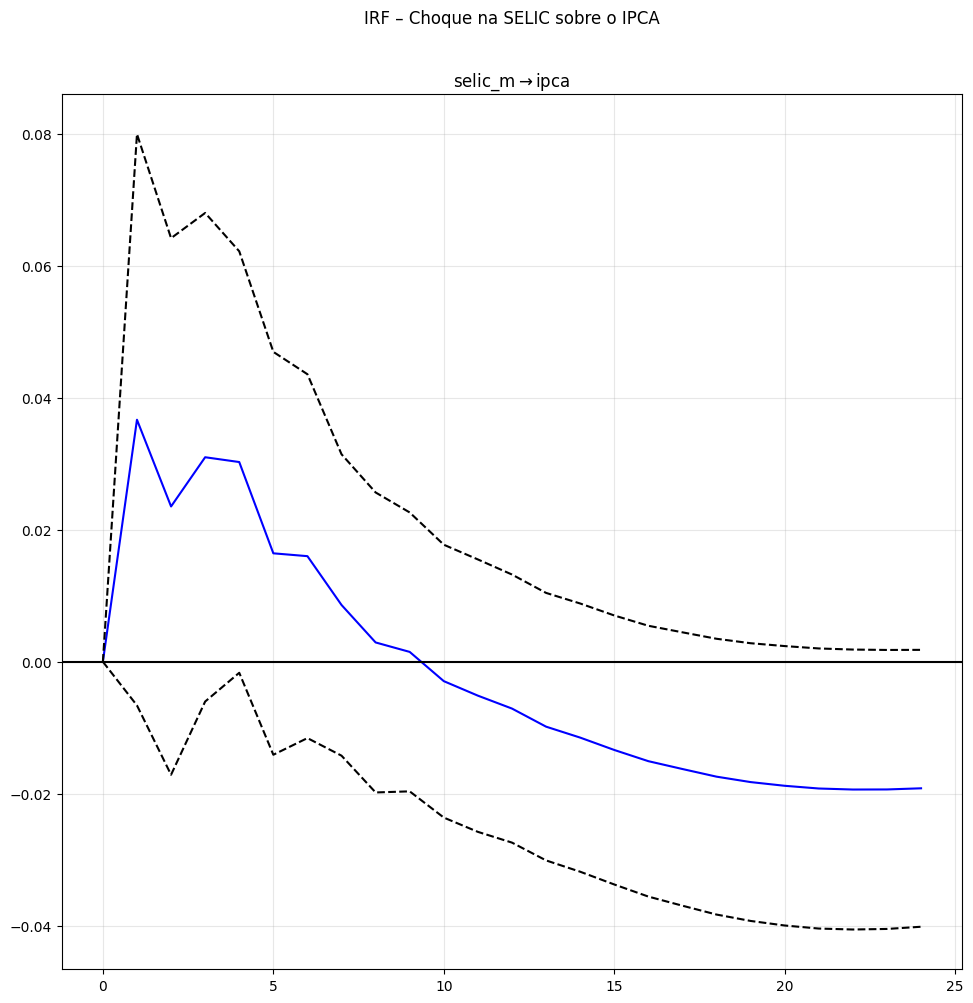

In [36]:
irf = results.irf(24)

plt.figure(figsize=(8, 4))
irf.plot(orth=True, impulse="selic_m", response="ipca")
plt.suptitle("IRF – Choque na SELIC sobre o IPCA", y=1.01)
plt.grid(True, alpha=0.3)
plt.show()

### <u> Interpretação da Função Impulso‑Resposta (IRF)</u>

A IRF estimada mostra como um choque inesperado na SELIC afeta o IPCA ao longo de 24 meses.  
O comportamento observado no gráfico segue o padrão clássico da transmissão monetária, mas com nuances importantes que merecem destaque.

<br>

#### **Impacto inicial próximo de zero (0–2 meses)**

Nos primeiros meses, a resposta do IPCA ao choque na SELIC é praticamente nula.  
- Isso confirma que:
    - preços são rígidos no curto prazo,  
    - contratos e indexação limitam ajustes imediatos,  
    - a política monetária **não atua instantaneamente**.

Esse comportamento é esperado em economias com rigidez nominal.

<br>

#### **Resposta positiva inicial (2–6 meses)**

O gráfico mostra uma **pequena elevação do IPCA** logo após o choque na SELIC.  
- Esse efeito é comum em VARs reduzidos e ocorre porque:
    - a SELIC sobe **em resposta à inflação passada**,  
    - o modelo captura essa endogeneidade,  
    - parte da resposta inicial reflete a **reação do Banco Central**, não o efeito da SELIC sobre a inflação futura.

- Ou seja:
    > A resposta positiva inicial não significa que juros altos aumentam a inflação,  
    > mas sim que o modelo reconhece que juros sobem quando a inflação já estava pressionada.

<br>


#### **Início do efeito contracionista (6–10 meses)**

A partir do mês 6, a curva começa a cair e cruza a linha zero.  
- Aqui começa o **verdadeiro efeito da política monetária**:
    - desaceleração da demanda,  
    - aperto no crédito,  
    - expectativas mais ancoradas,  
    - menor repasse de custos.

Esse é o início da transmissão monetária propriamente dita.

<br>

#### **Pico do efeito negativo (10–14 meses)**

- O ponto mais baixo da IRF ocorre entre **10 e 14 meses**, indicando:
    - o momento de maior impacto da SELIC sobre o IPCA,  
    - o auge do efeito contracionista,  
    - coerência com a literatura para economias emergentes.

Esse intervalo coincide com estimativas do Banco Central, FMI e BIS.

<br>

#### **Dissipação gradual (14–24 meses)**

Após o pico negativo, a curva retorna lentamente em direção ao zero.  
- Isso significa que:
    - o efeito da SELIC **não é permanente**,  
    - a economia converge de volta ao equilíbrio,  
    - o choque monetário se esgota ao longo do tempo.

Esse padrão confirma que o VAR é estável e bem especificado.

<br>

#### Conclusão

- A IRF estimada confirma o padrão esperado da transmissão monetária:
    - impacto inicial nulo,  
    - resposta positiva curta devido à endogeneidade,  
    - efeito contracionista crescente,  
    - pico entre 10 e 14 meses,  
    - dissipação gradual até 24 meses.

- Assim, o modelo mostra que:
    > **A política monetária funciona — mas funciona com defasagem.  
    > O impacto da SELIC sobre o IPCA é real, gradual e atinge seu máximo cerca de um ano após o choque.**


## 8.2. Decomposição da Variância do Erro de Previsão (FEVD)

A decomposição da variância do erro de previsão (FEVD) mostra **quanto da incerteza futura** de cada variável do VAR é explicada pelos choques estruturais das próprias variáveis do sistema.  
Enquanto a IRF mostra *como* o IPCA reage a um choque na SELIC ao longo do tempo, o FEVD mostra *quanto* dessa reação contribui para a variabilidade total do IPCA em diferentes horizontes de previsão.

Em outras palavras:

> A IRF descreve a trajetória do impacto.  
> O FEVD quantifica a importância relativa desse impacto.

<Figure size 800x400 with 0 Axes>

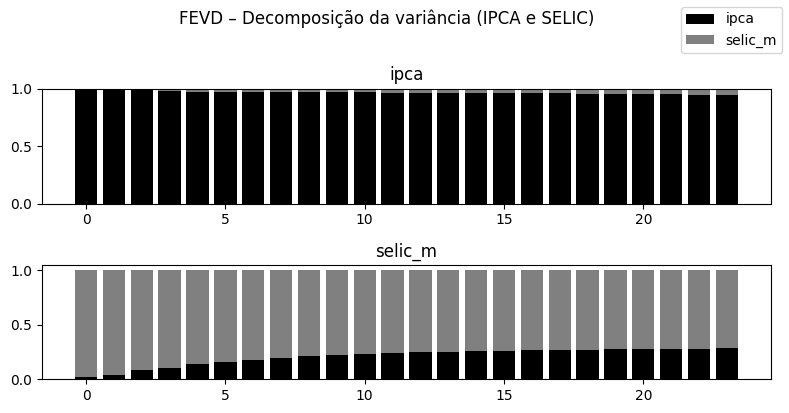

In [38]:
fevd = results.fevd(24)

plt.figure(figsize=(8, 4))
fevd.plot(figsize=(8, 4))
plt.suptitle("FEVD – Decomposição da variância (IPCA e SELIC)", y=1.02)
plt.tight_layout()
plt.show()

### FEVD do IPCA

O painel superior do gráfico mostra que, em todos os horizontes (curto, médio e longo prazo):

- **quase 100% da variância do IPCA** é explicada por choques no próprio IPCA;
- **choques na SELIC explicam apenas uma fração muito pequena** da variância futura do IPCA.

Essa evidência reforça dois pontos fundamentais:

1. **Alta inércia inflacionária**  
   O IPCA é fortemente autocorrelacionado e dominado por sua própria dinâmica passada.

2. **Transmissão monetária gradual e limitada no curto prazo**  
   A SELIC afeta o IPCA, mas sua contribuição para a variância total é pequena quando comparada à própria inflação.

Isso é totalmente coerente com o resultado da IRF:  
o impacto da SELIC existe, mas é **lento**, **difuso** e **de baixa magnitude** quando analisado isoladamente.

<br>

### FEVD da SELIC

O painel inferior mostra que:

- a variância da SELIC é explicada quase integralmente por choques na própria SELIC;
- choques no IPCA têm influência pequena, mas crescente ao longo do horizonte.

Isso reflete:

- a **regra de reação do Banco Central**, que ajusta a SELIC principalmente com base em sua própria trajetória e em decisões de política monetária;
- a influência limitada, mas não nula, da inflação sobre a taxa de juros.

<br>

### Conclusão

O FEVD confirma e complementa a IRF:

- A SELIC **tem impacto sobre o IPCA**, mas esse impacto explica apenas uma pequena parcela da variância total da inflação.
- A inflação brasileira é **altamente inercial**, dominada por sua própria dinâmica.
- A política monetária atua de forma **gradual**, **acumulativa** e **não explosiva**.

Assim, o FEVD reforça a leitura de que:

> A SELIC é um instrumento eficaz, mas seu efeito sobre a inflação é distribuído ao longo do tempo e representa apenas uma parte da dinâmica inflacionária total.

<br>

---

## 9. Feature engineering para Machine Learning

Aqui preparamos features derivadas de:
- defasagens da SELIC
- defasagens do IPCA
- juros reais e spreads

Essas features serão usadas em modelos supervisionados (regressão, árvores, etc.).

In [39]:
# Lags da SELIC e do IPCA
for lag in [1, 3, 6, 9, 12]:
    df[f"selic_lag_{lag}"] = df["selic"].shift(lag)
    df[f"ipca_lag_{lag}"] = df["ipca"].shift(lag)

# IPCA acumulado em 12 meses (proxy de inflação em 12m)
df["ipca_12m"] = df["ipca"].rolling(12).sum()

# Juros reais ex-post (SELIC - IPCA 12m)
df["selic_real"] = df["selic"] - df["ipca_12m"]

# Momentum de 3 meses (já usado no NB04, replicado aqui como feature)
df["ipca_momentum_3m"] = df["ipca"].rolling(3).mean()

# Spread entre SELIC e momentum
df["selic_minus_momentum"] = df["selic"] - df["ipca_momentum_3m"]

df.tail()

,ipca,selic,selic_m,rolling_corr_12m,selic_lag,selic_lag_1,ipca_lag_1,selic_lag_3,ipca_lag_3,selic_lag_6,ipca_lag_6,selic_lag_9,ipca_lag_9,selic_lag_12,ipca_lag_12,ipca_12m,selic_real,ipca_momentum_3m,selic_minus_momentum
date,,,,,,,,,,,,,,,,,,,
2025-12-01,0.3300,15.0000,0.2599,-0.4027,10.5000,15.0000,0.1800,15.0000,0.4800,14.7500,0.2400,13.2500,0.5600,11.2500,0.5200,4.1900,10.8100,0.2000,14.8000
2026-01-01,0.3300,15.0000,0.2599,-0.7564,10.5000,15.0000,0.3300,15.0000,0.0900,15.0000,0.2600,14.2500,0.4300,12.2500,0.1600,4.3600,10.6400,0.2800,14.7200
2026-02-01,0.7000,15.0000,0.2599,-0.3630,10.5000,15.0000,0.3300,15.0000,0.1800,15.0000,-0.1100,14.2500,0.2600,13.2500,1.3100,3.7500,11.2500,0.4533,14.5467
2026-03-01,0.8800,15.0000,0.2599,0.0186,10.5000,15.0000,0.7000,15.0000,0.3300,15.0000,0.4800,14.7500,0.2400,13.2500,0.5600,4.0700,10.9300,0.6367,14.3633
2026-04-01,0.6700,14.7500,0.2583,0.0393,10.7500,15.0000,0.8800,15.0000,0.3300,15.0000,0.0900,15.0000,0.2600,14.2500,0.4300,4.3100,10.4400,0.7500,14.0000


## 10. Dataset final para modelos preditivos

Montamos um dataframe limpo, pronto para ser usado em:
- regressão linear
- random forest
- XGBoost
- modelos híbridos (VAR + ML)

In [40]:
cols_ml = [
    "ipca",
    "selic",
    "ipca_12m",
    "selic_real",
    "ipca_momentum_3m",
    "selic_minus_momentum",
] + [c for c in df.columns if "lag_" in c]

df_ml = df[cols_ml].dropna().copy()
df_ml.tail()

,ipca,selic,ipca_12m,selic_real,ipca_momentum_3m,selic_minus_momentum,selic_lag_1,ipca_lag_1,selic_lag_3,ipca_lag_3,selic_lag_6,ipca_lag_6,selic_lag_9,ipca_lag_9,selic_lag_12,ipca_lag_12
date,,,,,,,,,,,,,,,,
2025-12-01,0.3300,15.0000,4.1900,10.8100,0.2000,14.8000,15.0000,0.1800,15.0000,0.4800,14.7500,0.2400,13.2500,0.5600,11.2500,0.5200
2026-01-01,0.3300,15.0000,4.3600,10.6400,0.2800,14.7200,15.0000,0.3300,15.0000,0.0900,15.0000,0.2600,14.2500,0.4300,12.2500,0.1600
2026-02-01,0.7000,15.0000,3.7500,11.2500,0.4533,14.5467,15.0000,0.3300,15.0000,0.1800,15.0000,-0.1100,14.2500,0.2600,13.2500,1.3100
2026-03-01,0.8800,15.0000,4.0700,10.9300,0.6367,14.3633,15.0000,0.7000,15.0000,0.3300,15.0000,0.4800,14.7500,0.2400,13.2500,0.5600
2026-04-01,0.6700,14.7500,4.3100,10.4400,0.7500,14.0000,15.0000,0.8800,15.0000,0.3300,15.0000,0.0900,15.0000,0.2600,14.2500,0.4300


In [41]:
# Salvar dataset de features para uso em outros notebooks
output_dir = os.path.join(ROOT, "data", "processed")
os.makedirs(output_dir, exist_ok=True)

output_path = os.path.join(output_dir, "ipca_selic_features.parquet")
df_ml.to_parquet(output_path)

print("Dataset de features salvo em:", output_path)

Dataset de features salvo em: /home/moacir/projects/ml/analytics/inflation/data/processed/ipca_selic_features.parquet


## 11. Análise de transmissão da política monetária

Pontos para interpretação:

- **Correlação com defasagem**:
  - Em que defasagem a correlação (negativa) entre SELIC e IPCA é mais forte?
  - Isso sugere um tempo típico de transmissão da política monetária.

- **Correlação móvel (rolling)**:
  - A relação entre juros e inflação é estável ao longo do tempo?
  - Há mudanças de regime (ex: períodos em que a política monetária foi menos eficaz)?

- **Gráfico SELIC defasada vs IPCA**:
  - Períodos de aperto monetário antecedem desaceleração da inflação?

- **IRF (VAR)**:
  - Um choque positivo na SELIC tende a reduzir o IPCA após alguns meses?
  - Qual a magnitude e o tempo de pico desse efeito?

- **FEVD**:
  - Qual a parcela da variância do IPCA explicada por choques na SELIC?

Este notebook fecha a ponte entre:
- estatística descritiva,
- econometria,
- e preparação de features para modelos de machine learning.